# TP final: fibrilación auricular en Holter

Agustín Carmusciano · Ingeniería de datos · Doctorado en Ingeniería Informática, ITBA

## Declaración de uso de IA

Usé Claude Code (Anthropic) en una sola conversación que dirigí yo, con tres modelos:

- "Claude Opus 5.5" para "relevar la consigna, buscar y comparar bases públicas de Holter, revisar el CSV clínico, armar el esqueleto del proyecto (`src/config.py`, los títulos del cuaderno y la celda de entorno) y proponer el modelo entidad-relación, el esquema estrella, el plan de limpieza, el diseño y el plan de implementación, que yo decidí o confirmé una por una; revisar el diseño antes del plan; coordinar la primera mitad de la programación (repartir las tareas, leer las revisiones y decidir las correcciones); escribir las celdas de código de este cuaderno y el cálculo de las cajas del tablero (`cinco_numeros` y `figura` en `src/tablero.py`, con sus pruebas), correr el cuaderno entero para verificar los conteos, revisar el cuaderno terminado y aplicar las correcciones de la revisión final; y adaptar el código y el cuaderno cuando decidí usar los RR sin corregir, coordinar y revisar ese cambio, redactar estas Instrucciones de la IA a partir de mis indicaciones, y hacer la figura fija con las 17 características que pedí al revisar el cuaderno y la prueba de Wilcoxon de día contra noche que le sumé (`figura_17`, `wilcoxon_dia_noche` y `holm` en `src/tablero.py`, con sus pruebas automáticas)".
- "Claude Opus 5.5" para "redactar, a partir de mis decisiones e indicaciones, los textos de justificación del cuaderno y el mensaje del tablero, que después revisé y corregí".
- "Claude Sonnet 5.5" para "escribir, tarea por tarea, el resto del código de `src/`, el SQL de `sql/` y el resto de las pruebas automáticas (locales: no están en el repositorio público), fijar las versiones de `requirements.txt`, actualizar el README y revisar cada una de esas tareas con otra instancia del mismo modelo".
- "Claude Fable 5.2" para "coordinar la segunda mitad de la programación (repartir las tareas, leer las revisiones y decidir las correcciones) y hacer la revisión final de todo el trabajo".

Las 17 características (`src/caracteristicas.py`) no se escribieron para este trabajo: son funciones del código de mi tesis, que también desarrollé con asistencia de IA (Claude Code), copiadas acá sin cambiar fórmulas ni parámetros.

## Instrucciones de la IA

Cómo trabajé: yo fijé el alcance y tomé las decisiones de diseño y de método, salvo las que tomó la IA al construir (paso 11); a la IA le pedí relevamientos, propuestas y código. En cada paso, qué decidí y qué le pedí a la IA. Entre comillas van mis palabras.

1. Requisitos. Le pasé la consigna y le pedí que extrajera lo que pide cada componente. Con esa lista decidí empezar por el cuaderno (Componente 1).
2. Alcance. Fijé el criterio de todo el trabajo: "cumplamos lo que dice la consigna, ni mas ni menos". Lo único fuera de la consigna: obtener los RR para calcular las 17 características que uso en mi tesis.
3. Datos. Le pregunté si había bases públicas de Holter con FA y de sanos. De las cinco que encontró y comparó elegí SHDB-AF sola, para comparar FA contra sin FA y día contra noche. La IA me advirtió que los pacientes `non-AF` de la base no son sanos, sino derivados a Holter: por eso los llamo sin FA.
4. Extracción. Decidí sacar los RR de los `.qrs` que trae la base. La IA revisó qué trae cada archivo de anotación y con eso confirmé que no hacía falta bajar la señal de ECG.
5. Cohorte. Para los 17 Holter con FA sin ritmo anotado evalué detectar los latidos con NeuroKit2. La IA mostró que a esos Holter no les faltan los latidos sino el ritmo, y midió cuántos latidos en FA tienen los PerAF anotados. Con esa medición decidí dejarlos afuera y justificarlo en el cuaderno.
6. Unidad de comparación. Decidí comparar por ventana de 30 s y no por Holter. Para las ventanas con más de un ritmo la IA propuso una regla y la acepté: una ventana entra sólo si todos sus latidos están en `AFIB` o todos en `N`.
7. Día, noche y tablero. Fijé la noche de 23 a 7 h. Le pedí que me explicara Dash y Streamlit, y elegí Dash dentro de Colab. Al revisar el cuaderno terminado noté que faltaba ver los boxplots de las 17, de día y de noche y en FA y sin FA. La IA me hizo notar que el tablero muestra una por vez y que en GitHub o en el PDF sale vacío, y propuso sumar una figura fija con las 17; la acepté. Después pedí sumarle una prueba de Wilcoxon de día contra noche en FA y en sin FA, con el p arriba de cada gráfico. La IA midió que por ventana casi todo da un p cercano a cero, porque las ventanas de un paciente no son independientes; elegí hacerla pareada por paciente, corregir por Holm las 34 pruebas y mostrar el p en la figura y en el tablero.
8. Bases. Le pedí una propuesta del modelo entidad-relación. Antes de aceptarla le hice explicar las relaciones y le planteé si las características iban en esa base; acepté su recomendación de que van al almacén. Confirmé la base transaccional de 6 tablas en 3FN y después el esquema estrella: una tabla de hechos con una fila por ventana de 30 s con un solo ritmo, y tres dimensiones (Holter, tiempo y ritmo).
9. RR. La IA había propuesto corregir los RR, la descarté y decidí usarlos tal como vienen, como hago hoy en mi tesis: los RR atípicos se identifican y se muestran, pero no se corrigen. Por eso la tabla `latido` guarda sólo la posición de cada latido y el RR se calcula al cargar el almacén. Talla y peso faltantes quedan nulos, sin imputar.
10. Textos. Le pedí que redactara los textos del cuaderno a partir de mis decisiones, cortos y sin tecnicismos, y que la declaración mostrara que salen de mis decisiones; confirmé la redacción que propuso. Los textos los reviso y corrijo yo.
11. Construcción y control. Aprobé el diseño y elegí construirlo con subagentes, por tareas, cada una con sus pruebas y una revisión. El plan pedía comprobar antes de dar algo por bueno que la copia de las 17 características da lo mismo que el código de mi tesis, que la base transaccional tiene los conteos esperados y que el cuaderno corre entero. Las decisiones que tomó la IA en el camino (por ejemplo, calcular en el servidor los cuartiles del tablero, bajar los archivos de a uno o usar la regla de 1,5 RIC para los atípicos de edad, talla y peso) las revisé.

## 0. Entorno

En Colab clono el repositorio, para importar el código de `src/`, e instalo las dependencias; en local uso la copia de trabajo. La lógica de cada etapa está en `src/` y el DDL de las dos bases en `sql/`: el cuaderno los llama y muestra lo que hacen.

In [1]:
import subprocess
import sys
from pathlib import Path


def correr(*comando):
    """Corre un comando; si falla, muestra lo que dijo antes de frenar."""
    r = subprocess.run(comando, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout, r.stderr)
        r.check_returncode()


if "google.colab" in sys.modules:
    repo = Path("/content/Ingenieria_de_datos")
    if not repo.exists():
        correr("git", "clone", "--depth", "1", "https://github.com/agusscarmu/Ingenieria_de_datos.git", str(repo))
    correr(sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "TP_FINAL" / "requirements.txt"))
    raiz = repo / "TP_FINAL"
else:
    raiz = Path.cwd().parent  # el cuaderno corre desde TP_FINAL/notebooks

sys.path.insert(0, str(raiz / "src"))
import config

for carpeta in (config.RAW, config.DB):
    carpeta.mkdir(parents=True, exist_ok=True)
print("Raíz del TP:", config.RAIZ)

Raíz del TP: /Users/agustincarmusciano/Desktop/PhD/Cursos/Ingenieria de datos/repo/TP_FINAL


## 1. Datos: SHDB-AF

Uso SHDB-AF v1.0.1, una base pública de PhysioNet con Holter de hasta unas 24 h de pacientes con FA paroxística (`PAF`), FA persistente (`PerAF`) y sin FA (`non-AF`), más un CSV con sus datos clínicos (`AdditionalData.csv`). Es afín a mi tesis (FA en Holter). Los pacientes sin FA no son sanos: son pacientes a los que se les pidió un Holter.

De cada Holter bajo sólo el encabezado (`.hea`), la posición de cada latido (`.qrs`) y, si está anotado, el ritmo (`.atr`). No bajo la señal de ECG: para los RR alcanza con la posición de los latidos.

In [2]:
import pandas as pd

import extraccion
import transformacion

ruta_csv = extraccion.descargar_csv()
crudo = pd.read_csv(ruta_csv)  # sin parámetros: todas las columnas, con los tipos que adivina pandas
print(f"{len(crudo)} Holter de {crudo['Subject_ID'].nunique()} pacientes, {crudo.shape[1]} columnas")
pd.crosstab(crudo["AF_Type"], crudo["Annotated"].map({True: "anotado", False: "sin anotar"}),
            margins=True, margins_name="total")

128 Holter de 122 pacientes, 45 columnas


Annotated,anotado,sin anotar,total
AF_Type,,,
PAF,69,11,80
PerAF,9,6,15
non-AF,20,13,33
total,98,30,128


La tabla cuenta los Holter por tipo de FA y según tengan o no el ritmo anotado. Para comparar ventanas en FA con ventanas sin FA necesito el ritmo de cada latido, que sólo está en los anotados (el `.atr`). Por eso armé así la cohorte:

- Entran los 98 anotados y los 13 sin FA sin anotar, a los que les asigno el ritmo `N` en todo el registro.
- Quedan afuera los 17 con FA sin anotar (11 PAF y 6 PerAF): sin `.atr` no sé qué partes del Holter están en FA.

En el `.atr`, `N` quiere decir "ritmo no marcado como otra cosa": incluye el sinusal, pero no está garantizado que sea sólo sinusal. Por eso a esas ventanas las llamo "sin FA (N)".

In [3]:
cohorte_cruda = transformacion.cohorte(crudo)
excluidos = transformacion.excluidos(crudo)
print("Excluidos por tipo de FA:", excluidos["AF_Type"].value_counts().to_dict())
display(cohorte_cruda.groupby("AF_Type").agg(holter=("Data_ID", "size"), pacientes=("Subject_ID", "nunique")))
print(f"Cohorte: {len(cohorte_cruda)} Holter de {cohorte_cruda['Subject_ID'].nunique()} pacientes")

registros = [f"{i:03d}" for i in cohorte_cruda["Data_ID"]]  # los archivos se llaman 001, 002, ...
anotados = {f"{i:03d}" for i in cohorte_cruda.loc[cohorte_cruda["Annotated"], "Data_ID"]}
extraccion.descargar_holters(registros, anotados=anotados)  # si un archivo ya está, no lo vuelve a bajar
archivos = [config.RAW / f"{r}.{ext}" for r in registros
            for ext in ("hea", "qrs") + (("atr",) if r in anotados else ())]
print(f"{len(archivos)} archivos de la cohorte en data/raw, {sum(f.stat().st_size for f in archivos) / 1e6:.0f} MB")

Excluidos por tipo de FA: {'PAF': 11, 'PerAF': 6}


,holter,pacientes
AF_Type,,
PAF,69,64
PerAF,9,9
non-AF,33,32


Cohorte: 111 Holter de 105 pacientes
40 de 320 archivos listos
80 de 320 archivos listos
120 de 320 archivos listos
160 de 320 archivos listos
200 de 320 archivos listos
240 de 320 archivos listos
280 de 320 archivos listos
320 de 320 archivos listos
320 archivos de la cohorte en data/raw, 91 MB


A los 17 excluidos no les puedo asignar el ritmo según su tipo de FA, como muestra la tabla de abajo con los 9 PerAF anotados: en 6, menos del 8 % de los latidos están en FA, así que un Holter de FA persistente no está necesariamente en FA todo el registro. Etiquetarlos con un detector automático sería circular (la etiqueta saldría de los mismos RR que después comparo), y anotarlos a mano queda fuera de este trabajo. Con los 13 sin FA sin anotar no pasa lo mismo: en los 20 sin FA anotados, todos los latidos están en `N`.

In [4]:
def porcentaje_en(registro, ritmo):
    """% de latidos de un Holter anotado que están en `ritmo`.
    Cada episodio del .atr dura hasta que empieza el siguiente."""
    h = extraccion.leer_holter(registro, anotado=True)
    episodios = transformacion.episodios(h)  # (latido donde empieza, ritmo)
    fines = [inicio for inicio, _ in episodios[1:]] + [len(h.qrs)]
    return 100 * sum(fin - inicio for (inicio, r), fin in zip(episodios, fines) if r == ritmo) / len(h.qrs)

sin_fa_anotados = crudo.loc[crudo["Annotated"] & (crudo["AF_Type"] == "non-AF"), "Data_ID"]
en_n = [porcentaje_en(f"{i:03d}", "N") for i in sin_fa_anotados]
print(f"Sin FA anotados: {len(en_n)} Holter; el que menos tiene, {min(en_n):.1f} % de sus latidos en N")
per_af = pd.DataFrame({"Holter": crudo.loc[crudo["Annotated"] & (crudo["AF_Type"] == "PerAF"), "Data_ID"]})
per_af["% de latidos en AFIB"] = [round(porcentaje_en(f"{i:03d}", "AFIB"), 1) for i in per_af["Holter"]]
per_af.sort_values("% de latidos en AFIB").reset_index(drop=True)

Sin FA anotados: 20 Holter; el que menos tiene, 100.0 % de sus latidos en N


,Holter,% de latidos en AFIB
0,114,0.7
1,27,0.8
2,130,0.8
3,126,1.5
4,125,5.3
5,113,7.0
6,43,37.0
7,34,79.7
8,6,80.1


## 2. Extracción

Hasta acá miré el CSV leído sin parámetros. Para cargarlo, leo sólo las 10 columnas que uso, cada una con su tipo: enteros chicos para los identificadores y la edad, `bool` para `Annotated`, `category` para el tipo de FA y el sexo (pocos valores que se repiten), `float32` para talla y peso, y texto para la hora de inicio y la duración. La tabla compara esos tipos con los que adivina `pd.read_csv`, y abajo está la memoria de cada forma de leerlo.

In [5]:
csv = extraccion.leer_csv(ruta_csv)
display(pd.DataFrame({"sin parámetros": crudo.dtypes[csv.columns], "elegido": csv.dtypes}))
pd.DataFrame({"columnas": [crudo.shape[1], csv.shape[1]],
              "memoria (KB)": [crudo.memory_usage(deep=True).sum() / 1024, csv.memory_usage(deep=True).sum() / 1024]},
             index=["pd.read_csv sin parámetros", "leer_csv"]).round(1)

,sin parámetros,elegido
Data_ID,int64,int16
Subject_ID,int64,int32
Annotated,bool,bool
AF_Type,object,category
Age_at_Holter,int64,int16
Sex,object,category
Height,float64,float32
Weight,float64,float32
Holter_start_time,object,string[python]
Holter_recording_length,object,string[python]


,columnas,memoria (KB)
pd.read_csv sin parámetros,45,128.7
leer_csv,10,17.1


Para qué uso cada columna: `Data_ID` y `Subject_ID` identifican el Holter y el paciente; `Annotated` dice si tiene el ritmo anotado; `AF_Type`, `Age_at_Holter` y `Sex` describen de quién es cada ventana en el almacén; `Holter_start_time` da la hora de cada ventana (día o noche), y `Holter_recording_length` sólo la uso para validar la duración (3.2). Talla y peso no entran al análisis, pero los cargo porque son las columnas clínicas con faltantes reales, y en 3.1 muestro cómo los trato.

Las otras 35 columnas no las cargo. No uso las de tratamientos y marcapasos, ablaciones, fechas (según la documentación de la base, están corridas para anonimizar), ecocardiograma, comorbilidades, antecedentes y motivo del Holter, ni los comentarios libres; y `BMI` y `Age_75_or_Older` se deducen de talla y peso, y de la edad (3.2).

De los Holter leo con `wfdb` el `.hea`, el `.qrs` y, si está, el `.atr`; las posiciones de los latidos quedan como enteros (número de muestra).

In [6]:
cohorte = transformacion.cohorte(csv)  # la misma cohorte de la sección 1, ahora con los tipos elegidos
holters = {}  # Data_ID -> Holter leído
for holter_id, anotado in zip(cohorte["Data_ID"], cohorte["Annotated"]):
    h = extraccion.leer_holter(f"{holter_id:03d}", anotado=bool(anotado))
    assert h.registro == f"{holter_id:03d}"
    holters[int(holter_id)] = h
print(f"{len(holters)} Holter leídos, {sum(len(h.qrs) for h in holters.values()):,} latidos, "
      f"fs = {sorted({h.fs for h in holters.values()})} Hz")

111 Holter leídos, 11,709,459 latidos, fs = [200] Hz


## 3. Transformación

Antes de cargar la base transaccional decido qué hacer con los valores faltantes y los datos atípicos del CSV y de los RR.

### 3.1 Valores faltantes

En las 10 columnas que cargo sólo faltan datos de talla y peso, en 4 Holter. No los imputo: no uso talla ni peso en el análisis, así que imputarlos sería inventar datos sin ganar nada. Quedan nulos en la base.

In [19]:
faltan = cohorte.isna().sum()
print("Faltantes en la cohorte:", faltan[faltan > 0].to_dict())

Faltantes en la cohorte: {'Height': 4, 'Weight': 4}


In [20]:
cohorte.loc[cohorte["Height"].isna() | cohorte["Weight"].isna(), ["Data_ID", "AF_Type", "Height", "Weight"]]

,Data_ID,AF_Type,Height,Weight
59,71,non-AF,NaN,NaN
71,99,non-AF,NaN,NaN
73,102,non-AF,NaN,NaN
103,136,PAF,NaN,NaN


En las columnas que no cargo hay muchos más faltantes (abajo, en el CSV entero), pero muchos son estructurales: el dato no falta, no corresponde. Por ejemplo, `PPM_Indication` (por qué se puso un marcapasos) sólo está vacía en pacientes sin marcapasos; al revés, 4 filas la tienen aunque `PPM_on_Holter` y `PPM_after_Holter` digan que no hay marcapasos, con `PPM_Date` posterior al Holter: probablemente se lo pusieron después y falta la marca en `PPM_after_Holter` (las dos primeras líneas de abajo). Como esas columnas no entran a la base, no hay nada que resolver.

In [8]:
con_marcapasos = crudo["PPM_on_Holter"] | crudo["PPM_after_Holter"]
vacia = crudo["PPM_Indication"].isna()
despues = pd.to_datetime(crudo["PPM_Date"]) > pd.to_datetime(crudo["Date_Holter"])
print(f"PPM_Indication vacía: {vacia.sum()} filas, {(vacia & con_marcapasos).sum()} con marcapasos "
      f"según PPM_on_Holter o PPM_after_Holter")
print(f"PPM_Indication con dato y sin marcapasos según esas columnas: {(~vacia & ~con_marcapasos).sum()} filas, "
      f"{(~vacia & ~con_marcapasos & despues).sum()} con PPM_Date posterior a Date_Holter")
no_cargadas = crudo.drop(columns=csv.columns).isna().sum()
no_cargadas[no_cargadas > 0].sort_values(ascending=False).rename("faltantes (de 128)")

PPM_Indication vacía: 121 filas, 0 con marcapasos según PPM_on_Holter o PPM_after_Holter
PPM_Indication con dato y sin marcapasos según esas columnas: 4 filas, 4 con PPM_Date posterior a Date_Holter


Ablation1_Others                     125
PPM_Date                             121
PPM_Indication                       121
Echo_LV_Asynergy                      99
Date_Redo_AF_Ablation                 96
Redo_Detail                           96
Antiarrhythmic_Drug_nonBB             93
Antiarrhythmic_Drug_BB                89
Date_1st_AF_Ablation                  67
Ablation1_PVI                         64
Ablation1_CTI                         64
Anticoagulation                       62
AF_Duration_Months                    61
Date_of_First_Diagnosis_of_AF_AFL     59
Comments                              55
BMI                                    4
Echo_LAD                               3
Echo_LVEF                              3
Echo_Date                              3
Moderate_or_Severe_MR                  3
Moderate_or_Severe_TR                  3
Moderate_or_Severe_AS                  3
Moderate_or_Severe_AR                  3
CHF                                    1
Name: faltantes 

### 3.2 Datos atípicos

`Holter_recording_length` tiene un formato irregular en 11 filas (por ejemplo, `24:4:59` en lugar de `24:04:59`). La leo con una regla flexible (horas, minutos y segundos, con o sin ceros a la izquierda) y la comparo con la duración que sale del `.hea` (muestras / frecuencia de muestreo). Guardo la del `.hea`; la del CSV sólo sirve para validar.

In [9]:
duraciones = transformacion.comparar_duraciones(cohorte, holters)
irregular = ~cohorte["Holter_recording_length"].str.fullmatch(r"\d{2}:\d{2}:\d{2}").to_numpy()
print("Holter por diferencia .hea - CSV (s):", duraciones["diferencia_s"].value_counts().to_dict())
duraciones.assign(texto_csv=cohorte["Holter_recording_length"].to_numpy())[irregular]

Holter por diferencia .hea - CSV (s): {1: 110, 0: 1}


,holter_id,csv_s,hea_s,diferencia_s,texto_csv
3,4,86699,86700,1,24:4:59
4,5,86699,86700,1,24:4:59
6,7,86529,86530,1,24:2:9
10,11,86699,86700,1,24:4:59
15,17,86699,86700,1,24:4:59
18,20,86699,86700,1,24:4:59
40,43,86699,86700,1,24:4:59
57,66,86699,86700,1,24:4:59
62,79,86699,86700,1,24:4:59
78,107,32399,32400,1,8:59:59


En los 111, las dos duraciones difieren en 1 s como mucho, también en las 11 irregulares: la regla las interpreta bien.

`Age_75_or_Older` contradice a la edad en 8 filas del CSV (tabla de abajo). No la cargo: se deduce de la edad, y guardar un dato que se puede calcular es lo que permite que dos columnas digan cosas distintas.

In [10]:
transformacion.edad_75_inconsistente(ruta_csv)

,Data_ID,Age_at_Holter,Age_75_or_Older
0,15,85,False
1,45,87,False
2,79,76,False
3,124,78,False
4,128,72,True
5,130,74,True
6,135,75,False
7,139,75,False


Para los datos atípicos de edad, talla y peso uso la misma regla que los bigotes del tablero (sección 6): es atípico lo que queda a más de 1,5 veces el rango intercuartil por debajo del primer cuartil o por encima del tercero. Hay dos edades (29 y 31 años) y cuatro pesos (de 98,7 a 112,6 kg) atípicos; son posibles en adultos, así que los dejo, y ninguno sale de un rango creíble (mínimos y máximos en la tabla).

In [11]:
for columna in ["Age_at_Holter", "Height", "Weight"]:  # la regla de los bigotes del tablero: 1,5 RIC
    v = cohorte[columna].astype("float64")
    q1, q3 = v.quantile([0.25, 0.75])
    afuera = v[(v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))]
    print(f"{columna}, atípicos: {', '.join(f'{x:g}' for x in sorted(afuera)) or 'ninguno'}")
cohorte[["Age_at_Holter", "Height", "Weight"]].describe().round(2)

Age_at_Holter, atípicos: 29, 31
Height, atípicos: ninguno
Weight, atípicos: 98.7, 98.7, 105.8, 112.6


,Age_at_Holter,Height,Weight
count,111.00,107.00,107.00
mean,66.36,1.64,61.83
std,12.15,0.09,14.34
min,29.00,1.45,35.90
25%,60.00,1.59,53.10
50%,68.00,1.63,60.50
75%,75.00,1.70,68.75
max,87.00,1.85,112.60


Los RR salen de las posiciones de los latidos del `.qrs`, que marcó un detector automático. Un RR es de una ventana de 30 s sólo si sus dos latidos están adentro; los que cruzan un borde, o quedan al final sin completar una ventana, no se usan (en la tabla, "RR fuera de ventanas"). Identifico como atípicos los RR de menos de 240 ms y los de más de 2.000 ms (250 y 30 latidos por minuto); la tabla muestra cuántos son. Los conservo, porque el análisis usa los RR tal como vienen, como en mi tesis: algunos pueden ser errores del detector y otros, pausas reales.

In [12]:
print(f"RR atípicos: menos de {config.RR_MIN_MS} ms ({60_000 // config.RR_MIN_MS} por minuto) "
      f"o más de {config.RR_MAX_MS} ms ({60_000 // config.RR_MAX_MS} por minuto)")
transformacion.rr_atipicos(holters).round(3)

RR atípicos: menos de 240 ms (250 por minuto) o más de 2000 ms (30 por minuto)


,RR en ventanas,RR fuera de ventanas,< 240 ms,> 2000 ms,"< 240 ms, % de los RR en ventanas","> 2000 ms, % de los RR en ventanas",RR más largo en ventanas (ms)
RR,11392275,317073,5359,6987,0.047,0.061,25025.0


## 4. Carga en la base transaccional (3FN)

La base transaccional es `data/db/transaccional.sqlite`, creada desde `sql/transaccional.sql` con sus claves primarias, foráneas y restricciones. Este es su modelo entidad-relación:

| Tabla | Clave primaria | Claves foráneas | Qué guarda |
|---|---|---|---|
| `paciente` | `paciente_id` | | el sexo |
| `tipo_fa` | `tipo_fa` | | PAF, PerAF y non-AF, con su descripción |
| `holter` | `holter_id` | `paciente_id` → `paciente`; `tipo_fa` → `tipo_fa` | anotado, edad, talla, peso, hora de inicio, frecuencia de muestreo y largo |
| `latido` | (`holter_id`, `n`) | `holter_id` → `holter` | la posición del latido en la señal |
| `ritmo` | `ritmo` | | los 7 ritmos del `.atr`, con su descripción |
| `episodio_ritmo` | (`holter_id`, `latido_inicio`) | (`holter_id`, `latido_inicio`) → `latido`; `ritmo` → `ritmo` | dónde empieza cada ritmo |

Un paciente tiene uno o más Holter; cada Holter tiene un tipo de FA y muchos latidos; cada episodio de ritmo empieza en un latido y tiene un ritmo, que vale hasta el episodio siguiente.

Está en 3FN, y por lo tanto en 2FN:

- 1FN: cada latido es una fila, sin listas dentro de una celda.
- 2FN: en las tablas con clave compuesta (`latido` y `episodio_ritmo`), ninguna columna depende de una parte de la clave. Por ejemplo, la frecuencia de muestreo depende sólo del Holter, así que está en `holter` y no en cada latido.
- 3FN: ninguna columna depende de otra que no sea la clave. El sexo es del paciente y no del Holter, y las descripciones están en sus catálogos.

No guardo datos que se pueden calcular, como el BMI o `Age_75_or_Older` (`anotado` no es un cálculo: viene del CSV). Por eso `latido` guarda sólo la posición de cada latido: el RR sale de dos latidos seguidos y lo calculo al cargar el almacén. La base se crea de cero cada vez que corre la celda, así que re-ejecutar el cuaderno no duplica filas.

In [13]:
import transaccional

con = transaccional.crear()  # borra la base anterior, si existe
transaccional.cargar_catalogos(con)
paciente, holter = transformacion.tablas_clinicas(cohorte, holters)
transaccional.cargar_clinicas(con, paciente, holter)
n_episodios = 0
for holter_id, h in holters.items():
    transaccional.cargar_latidos(con, holter_id, h.qrs)
    episodios = transformacion.episodios(h)
    transaccional.cargar_episodios(con, holter_id, episodios)
    n_episodios += len(episodios)

conteo = pd.DataFrame({"filas en la base": transaccional.contar(con)})
con.close()
conteo["esperadas"] = pd.Series({"tipo_fa": len(config.TIPOS_FA), "ritmo": len(config.RITMOS),
                                 "paciente": cohorte["Subject_ID"].nunique(), "holter": len(cohorte),
                                 "latido": sum(len(h.qrs) for h in holters.values()), "episodio_ritmo": n_episodios})
assert (conteo["filas en la base"] == conteo["esperadas"]).all()
assert conteo["filas en la base"].to_dict() == {"tipo_fa": 3, "ritmo": 7, "paciente": 105, "holter": 111,  # los totales
                                                "latido": 11_709_459, "episodio_ritmo": 1_818}       # del diseño
conteo

,filas en la base,esperadas
tipo_fa,3,3
ritmo,7,7
paciente,105,105
holter,111,111
latido,11709459,11709459
episodio_ritmo,1818,1818


Cada tabla tiene las filas que esperaba según lo que leí (los catálogos, la cohorte de la sección 1, los latidos de los `.qrs` y una fila por cada marca de ritmo de los `.atr`), y los totales son los que había contado al diseñar la base (el segundo `assert`).

## 5. Almacén de datos (modelo dimensional)

El almacén (`data/db/almacen.sqlite`, DDL en `sql/almacen.sql`) se carga sólo desde la base transaccional: es el segundo ETL. Es un esquema estrella:

- Tabla de hechos `hecho_ventana`: una fila por ventana de 30 s con un solo ritmo y al menos 5 RR (el grano), con `n_rr` y las 17 características como medidas. `n_ventana`, el número de la ventana en su Holter, es una dimensión degenerada: no tiene atributos ni tabla.
- `dim_holter`: de quién es la ventana. Junta `paciente`, `holter` y `tipo_fa` de la base transaccional; esa desnormalización hace que sea estrella y no copo de nieve.
- `dim_tiempo`: la hora del día en que empieza la ventana y su franja (noche de 23 a 7 h). Es la hora de inicio del Holter (hh:mm AM/PM en la base; la paso a 24 h) más el tiempo transcurrido, sin fecha: supongo que la anonimización corrió las fechas pero no la hora, y que el registro arranca en el segundo 0 de ese minuto.
- `dim_ritmo`: FA (`AFIB`) o sin FA (`N`).

Una ventana es FA si todos sus latidos están en `AFIB`, y sin FA (N) si todos están en `N`; descarto las demás, para que cada ventana tenga un solo ritmo, y las que tienen menos de 5 RR, el mínimo que uso en mi tesis. Los RR de cada ventana son los crudos: salen de dos latidos seguidos de la base transaccional. Las 17 características (`src/caracteristicas.py`, de mi tesis) miden cuánto y cómo cambian los RR de la ventana; como no saco ninguno, todos son vecinos. Abajo, las ventanas descartadas por cada motivo.

In [14]:
import almacen

conteos = almacen.construir()  # borra el almacén anterior y lo rehace leyendo la base transaccional
assert conteos.ventanas == conteos.descartadas_ritmo + conteos.descartadas_pocos_rr + conteos.hechos
pd.Series({"ventanas de 30 s": conteos.ventanas,
           "descartadas: mezcla u otro ritmo": conteos.descartadas_ritmo,
           "descartadas: menos de 5 RR": conteos.descartadas_pocos_rr,
           "hechos cargados": conteos.hechos}, name="ventanas").to_frame()

,ventanas
ventanas de 30 s,317134
descartadas: mezcla u otro ritmo,6590
descartadas: menos de 5 RR,5
hechos cargados,310539


Una característica queda nula en un hecho cuando la ventana no tiene con qué calcularla; por ejemplo, `P_SamEn` cuando ninguna plantilla coincide. No la imputo: el valor no existe, no es que falte. La tabla de abajo cuenta, por característica, en cuántos hechos quedó nula.

In [15]:
pd.Series(conteos.nulos, name="hechos con la característica nula").to_frame()

,hechos con la característica nula
P_cv,0
P_RMSSD,0
P_NMASD,0
P_IPD,0
PNN50,0
PNN100,0
P_SamEn,334
P_SSamEn,0
P_CSamEn,334
P_ShEn,0


## 6. Tablero

El tablero (`src/tablero.py`, hecho con Dash) lee sólo el almacén, con una consulta que une la tabla de hechos con sus tres dimensiones. Tiene un menú para elegir una de las 17 características y un boxplot con el ritmo en el eje x y una caja para el día y otra para la noche: un solo gráfico para las dos comparaciones, FA contra sin FA (N) y día contra noche. Arriba de cada ritmo muestra el p de día contra noche, que explico con la figura fija. Cada caja va del primer al tercer cuartil, con la mediana adentro; los bigotes llegan hasta el último valor que no es atípico según la regla de 3.2, y los atípicos no se dibujan. La primera tabla de abajo cuenta las ventanas detrás de cada caja. En la segunda, el 63 % de las ventanas sin FA (N) son de pacientes con FA que en ese momento estaban en N: por eso la etiqueta es el ritmo de la ventana, no el diagnóstico del paciente.

In [16]:
import tablero

hechos = tablero.leer_hechos()
display(pd.crosstab(hechos["etiqueta"], hechos["franja"], margins=True, margins_name="total"))
ventanas_n = hechos["etiqueta"] == "sin FA (N)"
ventanas_n_con_fa = ventanas_n & (hechos["tipo_fa"] != "non-AF")  # de Holter de pacientes con FA (PAF o PerAF)
print(f"Ventanas sin FA (N) de pacientes con FA: {ventanas_n_con_fa.sum():,} de {ventanas_n.sum():,} "
      f"({100 * ventanas_n_con_fa.sum() / ventanas_n.sum():.0f} %)")
pd.crosstab(hechos["tipo_fa"], hechos["etiqueta"], margins=True, margins_name="total")

franja,día,noche,total
etiqueta,,,
FA,35296,18807,54103
sin FA (N),171261,85175,256436
total,206557,103982,310539


Ventanas sin FA (N) de pacientes con FA: 161,472 de 256,436 (63 %)


etiqueta,FA,sin FA (N),total
tipo_fa,,,
PAF,48871,141030,189901
PerAF,5232,20442,25674
non-AF,0,94964,94964
total,54103,256436,310539


Antes del tablero, las 17 juntas en una figura fija, con las mismas cajas y los mismos colores. La agrego porque el tablero sólo se ve mientras corre: en GitHub o en el PDF del cuaderno su celda sale vacía. Con el menú del tablero se mira cada característica más de cerca.

Arriba de cada ritmo va el p de día contra noche, el mismo que muestra el tablero. Lo calculo por paciente y no por ventana, porque las ventanas de un mismo paciente no son independientes: con cientos de miles de ventanas, casi cualquier diferencia da un p cercano a cero. Para cada paciente con ventanas de ese ritmo de día y de noche tomo la mediana de cada franja, y comparo esos pares con la prueba de Wilcoxon de rangos con signo. Son 34 pruebas (17 características por 2 ritmos), así que corrijo los p con el método de Holm. Tomo como significativo un p corregido menor que 0,05.

Pacientes con ventanas de día y de noche: 34 en FA y 96 en sin FA (N)


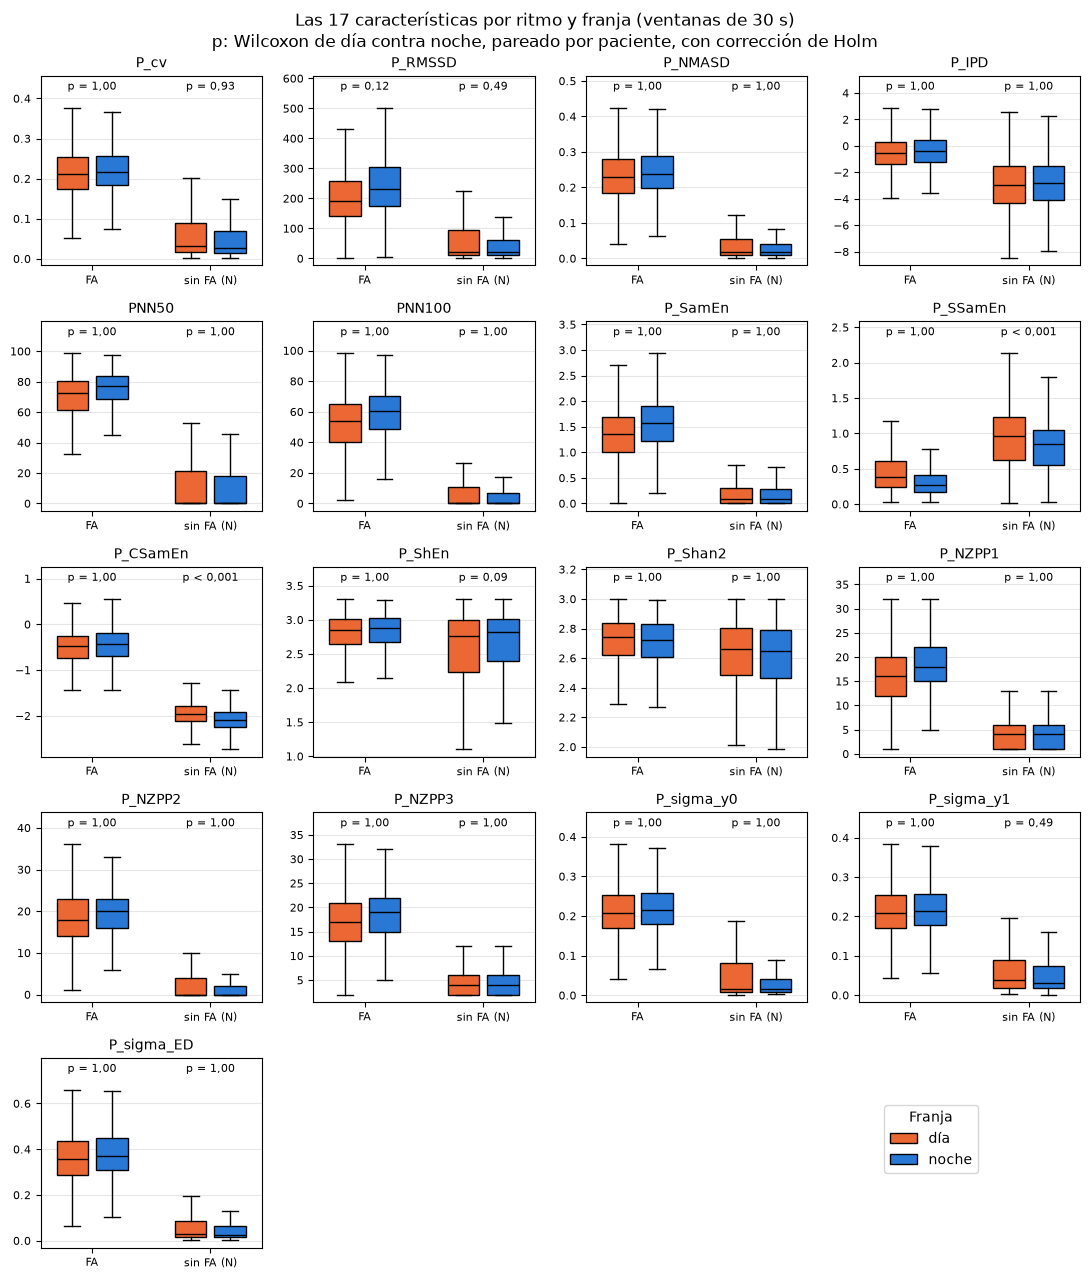

In [17]:
import matplotlib.pyplot as plt

pruebas = tablero.wilcoxon_dia_noche(hechos)  # día contra noche, pareada por paciente, con corrección de Holm
pacientes = pruebas.groupby("etiqueta")["n"].max()
print(f"Pacientes con ventanas de día y de noche: {pacientes['FA']} en FA y {pacientes['sin FA (N)']} en sin FA (N)")
tablero.figura_17(hechos, pruebas)
plt.show()

In [18]:
# lo que el mensaje dice de la prueba: sólo estas dos diferencias de día contra noche son significativas
assert set(pruebas.index[pruebas["p_holm"] < 0.05]) == {("sin FA (N)", "P_SSamEn"), ("sin FA (N)", "P_CSamEn")}
mensaje = (
    "En la mayoría de las 17 características, las cajas de las ventanas en FA quedan separadas de las de sin FA (N): "
    "en FA los RR son mucho más variables (por ejemplo, P_RMSSD, P_cv y PNN50 son mucho más altos). "
    "Donde más se superponen es en P_ShEn y P_Shan2. "
    "Entre el día y la noche, las cajas de un mismo ritmo cambian poco al lado de esa diferencia. "
    "Con la prueba de día contra noche, hecha por paciente porque las ventanas de un mismo paciente no son "
    "independientes, en FA ninguna diferencia es significativa, y en sin FA (N) sólo las de P_SSamEn y P_CSamEn, "
    "que bajan de noche."
)
app = tablero.crear_app(hechos, mensaje, pruebas)
app.run(jupyter_mode="inline", port=8050)  # al re-ejecutar la celda, Dash apaga el tablero anterior de este puerto

## Referencias

- SHDB-AF v1.0.1, PhysioNet: <https://physionet.org/content/shdb-af/1.0.1/>
- Barrera y Vecino Schandy, Proyecto Final de Carrera, ITBA, 2023: las fórmulas de las 17 características.
- Liberczuk, García, Barrera y Bonomini, SABI 2025: la lista de las 17 características.